# 06 — Under realistic circuit noise, the paper's model still describes the circuit

**Narrative points 7–8.** Simulation is not the final question: does the trade-off survive
realistic noise — gate errors, the same idle noise on data and ancillas, native gates — and
does the paper's two-parameter model still describe the circuit?

**Source:** `python -m qec_timing.studies.premise --gates textbook|native` →
`results/premise/premise_{textbook,native}.json`. X-basis memory, H2-1E gate ratios scaled
so p2 = 5e-3, idle noise linear (γ = 0.3 p2), quadratic (c = 0.01 p2) or both, T = 192,
2 × 100k shots per point. Full-circuit numbers equal the original notebooks 08/09 exactly.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
pr = {g: json.loads((R / "premise" / f"premise_{g}.json").read_text()) for g in ("textbook", "native")}
print(f"{'gates':<9}{'d':>2} {'idle':<10}{'dt* circuit':>12}{'predicted':>11}{'error':>8}{'b_read':>8}{'max P2 dev':>12}")
for g, data in pr.items():
    for r in data["rows"]:
        f, p = r["full"]["optimum"], r["predicted"]["optimum"]
        dev = max(max(abs(x["p_read / p_read(1)"] - 1), abs(x["p_data / [p_data(1) xor q_wait]"] - 1)) for x in r["p2_checks"])
        print(f"{g:<9}{r['d']:>2} {r['idle']:<10}{f['dt_star']:>12.2f}{p['dt_star']:>11.2f}"
              f"{p['dt_star']/f['dt_star']-1:>+8.0%}{r['calibration']['b_read']:>8.3f}{dev:>12.2%}")

gates     d idle       dt* circuit  predicted   error  b_read  max P2 dev
textbook  3 lin 0.3          10.12      11.80    +17%   0.967       0.51%
textbook  3 quad 0.01         8.25       9.50    +15%   1.020       0.76%
textbook  3 mixed             5.50       6.58    +20%   0.969       0.50%
textbook  5 lin 0.3           5.35       5.43     +1%   0.937       0.09%
textbook  5 quad 0.01         7.19       7.90    +10%   0.989       0.33%
textbook  5 mixed             3.80       4.05     +7%   0.938       0.27%
textbook  7 lin 0.3           3.48       3.28     -5%   0.935       0.27%
textbook  7 quad 0.01         6.59       6.68     +1%   0.984       0.16%
textbook  7 mixed             2.82       2.80     -1%   0.933       0.27%
native    3 lin 0.3           9.73      11.57    +19%   0.963       0.66%
native    3 quad 0.01         8.43       9.72    +15%   0.991       0.76%
native    3 mixed             5.40       6.43    +19%   0.962       0.59%
native    5 lin 0.3           5.15    

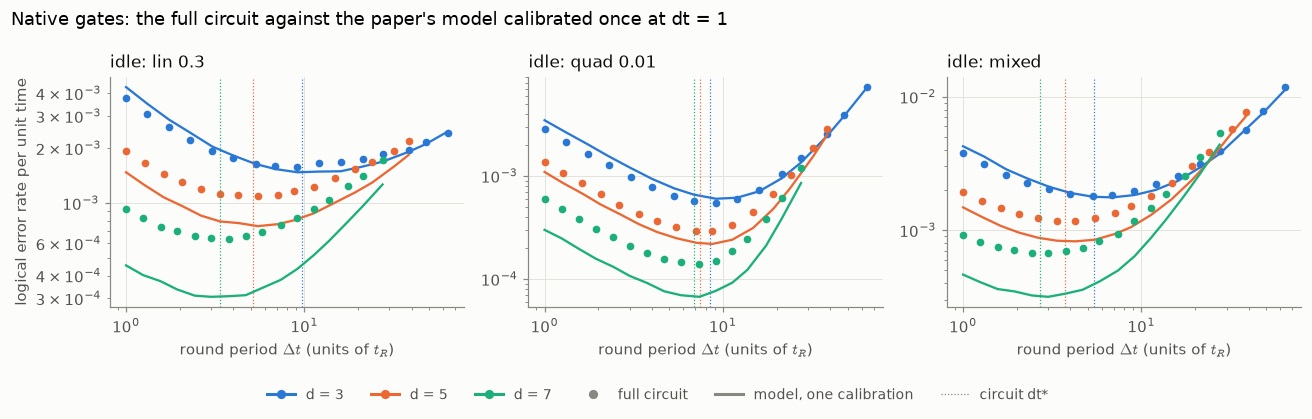

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=False)
for ax, idle in zip(axes, ("lin 0.3", "quad 0.01", "mixed")):
    for r in pr["native"]["rows"]:
        if r["idle"] != idle:
            continue
        c = P.D_COLOR[r["d"]]
        full = r["full"]["points"]; pred = r["predicted"]["points"]
        ax.plot([q["dt"] for q in full], [q["r"] for q in full], "o", color=c, ms=4)
        ax.plot([q["dt"] for q in pred], [q["r"] for q in pred], "-", color=c, lw=1.5)
        o = r["full"]["optimum"]["dt_star"]; ax.axvline(o, color=c, lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"idle: {idle}", loc="left")
    ax.set_xlabel(r"round period $\Delta t$ (units of $t_R$)")
axes[0].set_ylabel("logical error rate per unit time")
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=P.D_COLOR[d], marker="o", ls="-", label=f"d = {d}") for d in (3, 5, 7)]
handles += [Line2D([], [], color=P.MUTED, marker="o", ls="", label="full circuit"),
            Line2D([], [], color=P.MUTED, ls="-", label="model, one calibration"),
            Line2D([], [], color=P.MUTED, ls=":", lw=0.8, label="circuit dt*")]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.04), fontsize=9)
fig.suptitle("Native gates: the full circuit against the paper's model calibrated once at dt = 1", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.06, 1, 1))
P.save(fig, "06_premise_realistic_noise_1")

**Reading** (narrative point 8).
- *Measured:* every one of the 18 curves (2 gate sets × 3 distances × 3 idle models) has an
  interior optimum. Realistic noise does not remove the trade-off.
- *Measured:* the paper's model, calibrated **once** at back-to-back rounds (p_data(1),
  p_read from detection events, plus the idle channel for the wait), predicts dt* to
  +15–20% at d = 3, +1–10% at d = 5 and −5…+3% at d = 7. The prediction improves with distance.
- *Measured (P2):* readout and data error rates stay within 0.8% of the one-calibration
  model at longer intervals: the two-number description holds, given the right numbers.
- *Measured, a limit:* the model places the optimum well but underestimates the error rate
  itself, more so with distance (the lines sit below the points at d = 7; the original
  notebook 08 measured prediction/circuit p_L = 0.51 there). Use it to choose dt*, not to
  quote p_L.
- *Where it differs from the paper's assumptions:* the effective rates are not the paper's.
  The data error per round is not uniform across data qubits, native decomposition adds
  gate faults, and two-qubit gates spread errors unevenly, so p_data and b_read must be
  measured from the circuit, not set to p and 1. A hand-built phenomenological decoder
  misses mid-round faults; decoding uses the circuit's full detector error model
  (`backends/stim_circuit`, `stim_native`).
- *Caveat:* in these Stim models ancillas reset every round and the wait is memoryless, so
  P2 is partly structural; whether a device keeps the parameters stable is what hardware
  test T9–T10 would show.